# Iris Flower Classification

Objective:

The objective of this project is to develop a machine learning classification model that can identify the species of an Iris flower based on its physical measurements.

The three species are:
- Iris Setosa
- Iris Versicolor
- Iris Virginica
We will explore the dataset, visualise its features, train classification models and evaluate their performance.

## 1. Importing Libraries

In this project, we use Python libraries for data manipulation,
visualization, and machine learning.

In [49]:
# Data manipulation
import pandas as pd
import numpy as np


In [50]:

# Data visualisation
import matplotlib.pyplot as plt
import seaborn as sns


In [51]:

# Load dataset
from sklearn.datasets import load_iris


In [52]:


# Machine learning
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier


In [53]:

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)


In [54]:

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Loading the Iris Dataset

  The Iris dataset is a built-in dataset available in Scikit-learn.
  It contains 150 flower observations belonging to three species:
  Setosa, Versicolor, and Virginica.

In [55]:
from sklearn.datasets import load_iris

# Load the Iris dataset
iris = load_iris()

print("Iris dataset loaded successfully!")

Iris dataset loaded successfully!


In [56]:
# Display the feature names
print("Feature names:")
print(iris.feature_names)

# Display the target names
print("\nSpecies names:")
print(iris.target_names)

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Species names:
['setosa' 'versicolor' 'virginica']


In [57]:
# Convert flower measurements into a DataFrame
df = pd.DataFrame(
    iris.data,
    columns=iris.feature_names
)

# Display the first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [58]:
# Add species names to the DataFrame
df["species"] = pd.Categorical.from_codes(
    iris.target,
    iris.target_names
)

# Display first five rows
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the structure,
quality, and characteristics of our dataset.

In [59]:
# Check the number of rows and columns
df.shape

(150, 5)

In [60]:
# Display information about the dataset
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   sepal length (cm)  150 non-null    float64 
 1   sepal width (cm)   150 non-null    float64 
 2   petal length (cm)  150 non-null    float64 
 3   petal width (cm)   150 non-null    float64 
 4   species            150 non-null    category
dtypes: category(1), float64(4)
memory usage: 5.0 KB


In [61]:
# Count missing values in each column
df.isnull().sum()

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
dtype: int64

In [62]:
# Generate descriptive statistics
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


In [63]:
# Count the number of flowers in each species
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 4. Data Visualization

In this section, we use data visualization techniques to explore the Iris dataset and understand the distribution and relationships between different flower measurements.

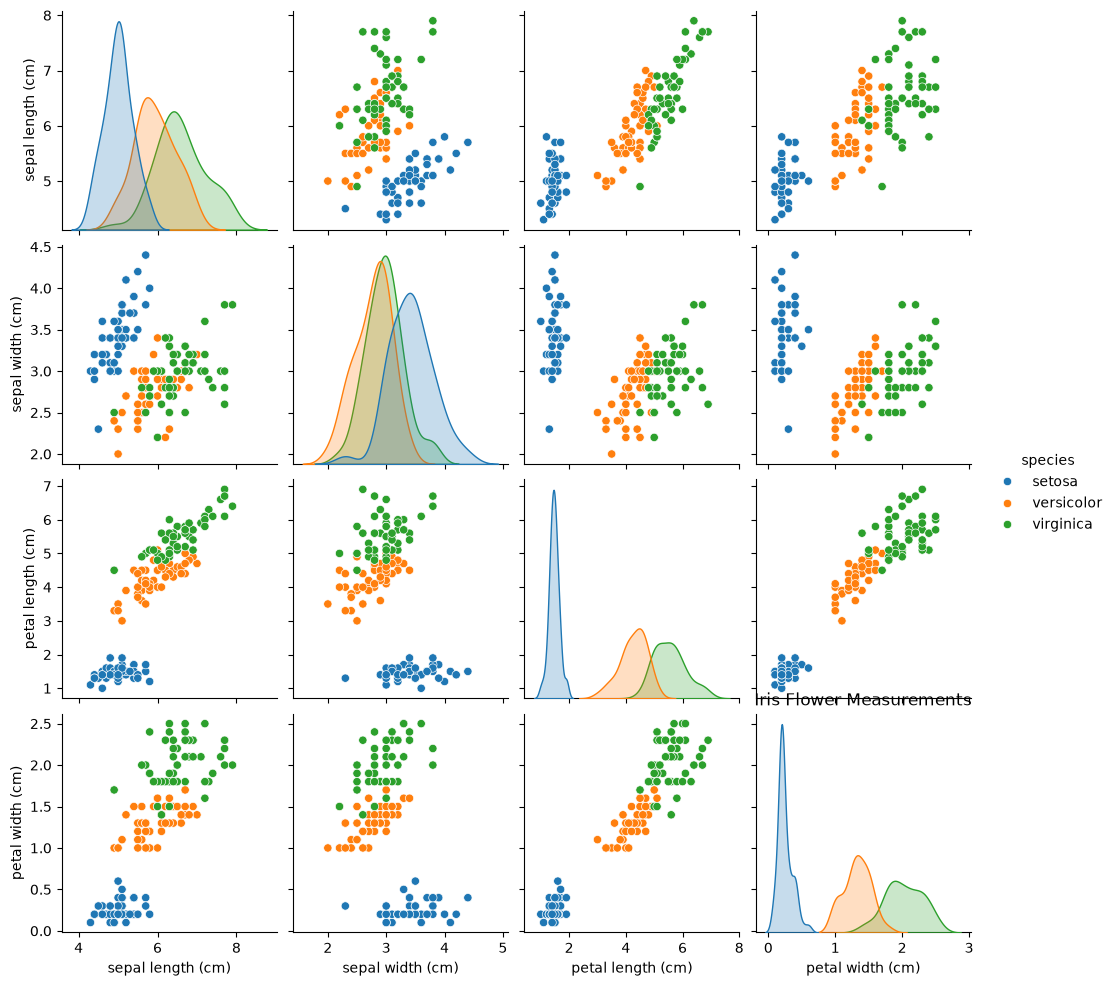

In [64]:
# Create a pairplot to compare flower measurements
sns.pairplot(df, hue="species")

# Give the graph a title
plt.title("Iris Flower Measurements")

# Display the graph
plt.show()

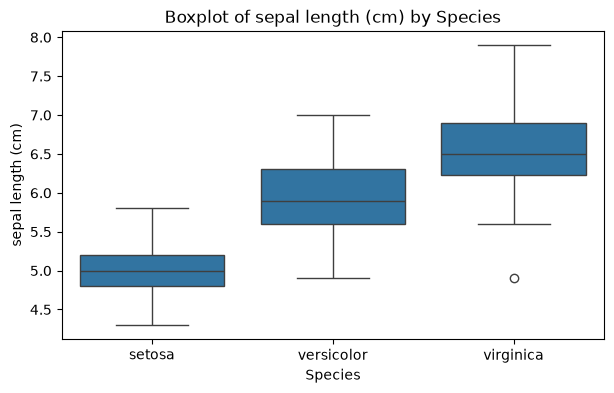

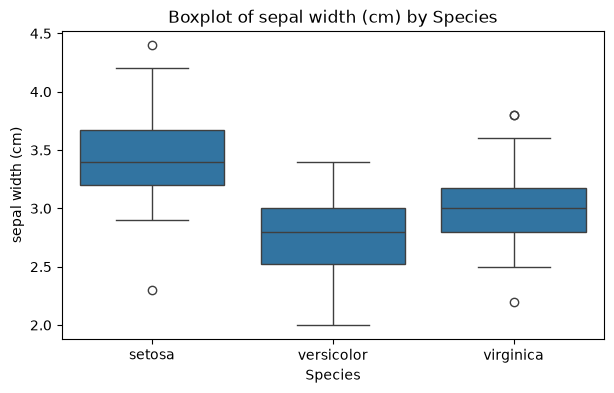

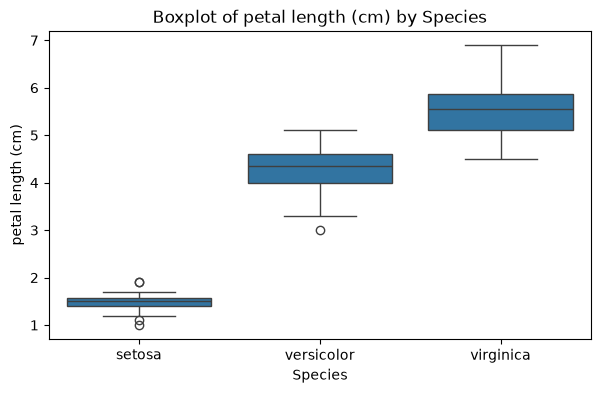

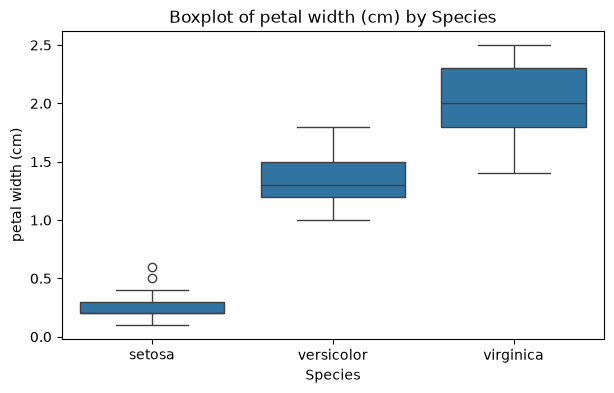

In [65]:
# List of numerical features
features = iris.feature_names

# Create a separate boxplot for each feature
for feature in features:
    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df, x="species", y=feature)

    plt.title(f"Boxplot of {feature} by Species")
    plt.xlabel("Species")
    plt.ylabel(feature)

    plt.show()

## 5. Feature Selection Discussion

Feature selection helps identify the most useful measurements for classifying Iris flower species.

Based on the pairplot and boxplots, petal length and petal width are the most discriminative features because they show clearer differences among Setosa, Versicolor, and Virginica.

Sepal length and sepal width are less discriminative because their values overlap more between different species.

Therefore, petal length and petal width are expected to be particularly useful features for building an accurate classification model.

## 6. Train-Test Split

In this step, we divide the dataset into two parts:

Training data (80%): Used to train the machine learning models.
Testing data (20%): Used to evaluate how well the models perform on unseen data.

We use stratification to maintain the same proportion of each Iris species in both sets.

In [66]:
# Separate features (X) and target (y)
X = iris.data
y = iris.target

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the sizes of the training and testing sets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training features: (120, 4)
Testing features: (30, 4)
Training labels: (120,)
Testing labels: (30,)


## 7. Model Training

In this section, we train two machine learning classification models:

1. Logistic Regression
2. Random Forest Classifier

We will train both models and compare their performance.

### 7.1 Logistic Regression

Logistic Regression is a classification algorithm that predicts which category an observation belongs to.

Before training the model, we use StandardScaler to put all numerical features on a similar scale.

Some machine learning algorithms, such as Logistic Regression, can work better when features are on comparable scales.

StandardScaler transforms the features so that each has approximately a mean of 0 and a standard deviation of 1.

In [67]:
# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Create the Logistic Regression model
log_model = LogisticRegression(max_iter=200)

# Train the model
log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### 7.2 Random Forest Classifier

Random Forest is a machine learning classification algorithm that uses multiple Decision Trees to make predictions.

Each Decision Tree makes a prediction, and the Random Forest combines their results to produce the final prediction.

Unlike Logistic Regression, Random Forest does not require feature scaling.

In [68]:
# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


## 8. Model Evaluation

In this section, we evaluate the performance of both trained models using the testing dataset.

We use accuracy, confusion matrix, precision, recall, and F1-score to measure model performance.

### 8.1 Logistic Regression Evaluation

We use the trained Logistic Regression model to predict the species of the testing samples.

In [69]:
# Make predictions using Logistic Regression
log_predictions = log_model.predict(X_test_scaled)

# Display actual and predicted values
print("Actual values:", y_test)
print("Predicted values:", log_predictions)

Actual values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 1 2 2 1 0 2 0]


### 8.2 Logistic Regression Accuracy

Accuracy measures how many predictions the model made correctly out of all testing samples.

In [70]:
# Calculate Logistic Regression accuracy
log_accuracy = accuracy_score(y_test, log_predictions)

print("Logistic Regression Accuracy:", log_accuracy)
print("Accuracy Percentage:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 0.9333333333333333
Accuracy Percentage: 93.33333333333333 %


### 8.3 Logistic Regression Confusion Matrix

A confusion matrix is used to compare the actual species with the species predicted by the model.

It helps us identify correct and incorrect predictions for each Iris species.

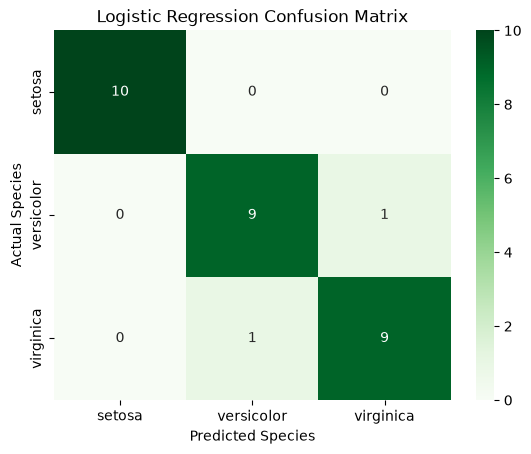

In [71]:
# Calculate the confusion matrix
log_cm = confusion_matrix(y_test, log_predictions)

# Display confusion matrix as a heatmap
sns.heatmap(
    log_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

### 8.4 Logistic Regression Classification Report

The classification report evaluates the performance of the Logistic Regression model using the following metrics:

1. **Precision:** Measures how many predicted samples of a species were correctly classified.
2. **Recall:** Measures how many actual samples of a species were correctly identified.
3. **F1-score:** Represents the balance between precision and recall.
4. **Support:** Shows the number of actual samples for each species.

These metrics provide a detailed understanding of the model's classification performance.

In [72]:
# Generate the classification report
log_report = classification_report(
    y_test,
    log_predictions,
    target_names=iris.target_names
)

print(log_report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### 8.5 Random Forest Evaluation

In this step, we use the trained Random Forest model to predict the species of the testing samples.

In [73]:
# Make predictions using Random Forest
rf_predictions = rf_model.predict(X_test)

# Display actual and predicted values
print("Actual values:", y_test)
print("Predicted values:", rf_predictions)

Actual values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 2 1 0 2 0]


### 8.6 Random Forest Accuracy

Accuracy measures the proportion of correct predictions made by the Random Forest model out of all testing samples.

In [74]:
# Calculate Random Forest accuracy
rf_accuracy = accuracy_score(y_test, rf_predictions)

print("Random Forest Accuracy:", rf_accuracy)
print("Accuracy Percentage:", rf_accuracy * 100, "%")

Random Forest Accuracy: 0.9
Accuracy Percentage: 90.0 %


### 8.7 Random Forest Confusion Matrix

The confusion matrix compares the actual species with the species predicted by the Random Forest model. It helps identify correct and incorrect predictions for each species.

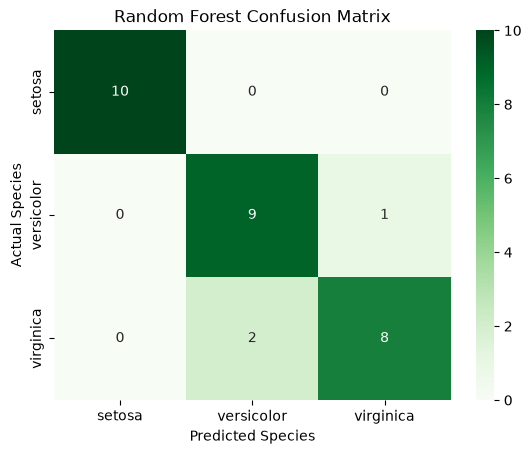

In [45]:
# Calculate the confusion matrix
rf_cm = confusion_matrix(y_test, rf_predictions)

# Display confusion matrix as a heatmap
sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

### 8.8 Random Forest Classification Report

The classification report evaluates the Random Forest model using precision, recall, F1-score, and support.

These metrics help us understand how effectively the model classifies each Iris species.

In [47]:
# Generate the classification report
rf_report = classification_report(
    y_test,
    rf_predictions,
    target_names=iris.target_names
)

print(rf_report)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30



## 9. Model Comparison

In this section, we compare the performance of Logistic Regression and Random Forest using their accuracy scores.

We also compare precision, recall, and F1-score to identify the better-performing model.

In [48]:
# Create a comparison table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy, rf_accuracy]
})

# Display the comparison
comparison

,Model,Accuracy
0,Logistic Regression,0.933333
1,Random Forest,0.900000


## 10. Best Model Selection

The performance of Logistic Regression and Random Forest was compared using their accuracy scores.

- Logistic Regression achieved an accuracy of **93.33%**.
- Random Forest achieved an accuracy of **90.00%**.

Based on the accuracy results, Logistic Regression performed better than Random Forest on the testing dataset.

Therefore, Logistic Regression was selected as the best-performing model for this experiment.

The confusion matrices and classification reports were also used to examine the classification performance of both models.

## 11. Conclusion

In this project, we developed machine learning classification models to predict Iris flower species using four numerical features:

- Sepal length
- Sepal width
- Petal length
- Petal width

We trained and evaluated two classification algorithms: Logistic Regression and Random Forest.

Their performance was compared using accuracy, confusion matrices, precision, recall, and F1-score.

This project demonstrated how machine learning can be used to classify flower species based on their physical measurements.